<center><h1>Blombach_George_HW4</h1></center>
<br>
<br>

Name: George Blombach
Github Username: gblombach
USC ID: 2416096199

## 1. Time Series Classification Part 1: Feature Creation/Extraction (HW3 Rerun)

### (a) Obtain Data

Import packages

In [19]:
# pip install numpy pandas
import os
import numpy as np
import pandas as pd
from scipy.stats import bootstrap

#new for HW4
import seaborn as sns
import matplotlib.pyplot as plt
import statsmodels.api as sm

from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.feature_selection import RFE, RFECV
from sklearn.model_selection import StratifiedKFold, cross_validate
from sklearn.metrics import accuracy_score, balanced_accuracy_score, confusion_matrix, classification_report, roc_curve, auc, roc_auc_score, ConfusionMatrixDisplay
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler


Get the AReM Data Set

In [2]:
# initialize
path = "../data"
test_data = pd.DataFrame()
train_data = pd.DataFrame()
feature = 0 #for adding feature number to dataset

### (b) Splitting Data

In [3]:
#augmented to add lables for activity and data_type
# activity = 0: other activities
# activity = 1: bending
# type = 0: training data
# type = 1: testing data

# iterate and load datasets
for folder in os.scandir(path):
    if folder.is_dir():
        for file in os.scandir(folder):
            if folder.name == 'bending1' or folder.name == 'bending2':
                #extract data
                csvdata = pd.read_csv(os.path.join(path,folder.name,file.name),skiprows=4, usecols=range(7))
                csvdata['Activity'] = 1 # bending activity = 1
                if file.name == 'dataset1.csv' or file.name == 'dataset2.csv':
                    #add instance number
                    feature += 1
                    csvdata['Instance'] = feature
                    csvdata['Type'] = 1
                    #add to testing dataframe
                    test_data = pd.concat([test_data, csvdata], ignore_index = True)
                else:
                    #add instance number
                    feature += 1
                    csvdata['Instance'] = feature
                    csvdata['Type'] = 0
                    #add to training dataframe
                    #print(folder.name, file.name, len(csvdata))
                    train_data = pd.concat([train_data, csvdata], ignore_index = True)
            elif file.name == 'dataset1.csv' or file.name == 'dataset2.csv' or file.name == 'dataset3.csv':
                #print("test", folder.name, file.name)
                csvdata = pd.read_csv(os.path.join(path,folder.name,file.name),skiprows=4, usecols=range(7))
                csvdata['Activity'] = 0 #not bending activity = 0
                #print(csvdata)
                #add instance number
                feature += 1
                csvdata['Instance'] = feature
                csvdata['Type'] = 1
                #add to dataframe
                test_data = pd.concat([test_data, csvdata], ignore_index = True)
            else:
                csvdata = pd.read_csv(os.path.join(path,folder.name,file.name),skiprows=4, usecols=range(7))
                #print(folder.name, file.name, len(csvdata))
                #print(csvdata)
                #add instance number
                feature += 1
                csvdata['Instance'] = feature
                csvdata['Type'] = 0
                csvdata['Activity'] = 0 #not bending activity = 0
                #add to dataframe
                train_data = pd.concat([train_data, csvdata], ignore_index = True)
                #print("train", folder.name, file.name)
            #print(folder.name, file.name, feature)
#ensure numeric
train_data = train_data.apply(pd.to_numeric, errors='coerce')
test_data = test_data.apply(pd.to_numeric, errors='coerce')

#print(test_data)
print("Train Data: ", train_data.shape)
print("Test Data: ", test_data.shape)

#use this to see all output rows
full_data = pd.concat([train_data, test_data], ignore_index=True)
print("Full Data: ", full_data.shape)

#full_data.head()
pd.set_option('display.max_rows', None)
#print(test_data['Instance'].value_counts().sort_index())

Train Data:  (33119, 10)
Test Data:  (9120, 10)
Full Data:  (42239, 10)


### (c) Feature Extraction

In [4]:
chart = pd.DataFrame()
grouped_by_instance = full_data.groupby('Instance')
#display(grouped_by_instance.head())
#grouped_by_instance = full_data.groupby('Instance').mean()
#print(grouped_by_instance.head())

features = ['min', 'max', 'mean', 'median', 'std', '1stQrt', '3rdQrt']

#for i in range(len(grouped_by_instance)):
#    print(chart[grouped_by_instance].mean(axis=1))
#    for j in range(6):
#        chart[f'mean{j}'] = grouped_by_instance.iloc[j+1]
    #print(grouped_by_instance.iloc[1])

for j in range (88):
    chart.loc[j, "Instance"] = grouped_by_instance.get_group(j+1)['Instance'].iloc[0]
    chart.loc[j, "Activity"] = grouped_by_instance.get_group(j+1)['Activity'].iloc[0]
    chart.loc[j, "Type"] = grouped_by_instance.get_group(j+1)['Type'].iloc[0]
    chart.loc[j, 'Activity'] = chart.loc[j, 'Activity'].astype('int')
    for i in range (1,7):
        chart.loc[j, f'{features[0]}{i}'] = grouped_by_instance.get_group(j+1).iloc[:,i:i+1].min().values
        chart.loc[j, f'{features[1]}{i}'] = grouped_by_instance.get_group(j+1).iloc[:,i:i+1].max().values
        chart.loc[j, f'{features[2]}{i}'] = grouped_by_instance.get_group(j+1).iloc[:,i:i+1].mean().values
        chart.loc[j, f'{features[3]}{i}'] = grouped_by_instance.get_group(j+1).iloc[:,i:i+1].median().values
        chart.loc[j, f'{features[4]}{i}'] = grouped_by_instance.get_group(j+1).iloc[:,i:i+1].std().values
        chart.loc[j, f'{features[5]}{i}'] = grouped_by_instance.get_group(j+1).iloc[:,i:i+1].quantile(.25).values
        chart.loc[j, f'{features[6]}{i}'] = grouped_by_instance.get_group(j+1).iloc[:,i:i+1].quantile(.75).values
#fix integer in Instance col
chart['Instance'] = chart['Instance'].astype(int)
chart['Activity'] = chart['Activity'].astype(int)

#display chart without index, rounded to 3 places
display(chart.head().style
        .format(precision=3) # round it
        .hide(axis='index')
        .hide(axis='columns',
             subset = ['Activity','Type']) # hide ordinal
        .set_properties(**{'text-align': 'center'}) # center the data in the columns
        )


Instance,min1,max1,mean1,median1,std1,1stQrt1,3rdQrt1,min2,max2,mean2,median2,std2,1stQrt2,3rdQrt2,min3,max3,mean3,median3,std3,1stQrt3,3rdQrt3,min4,max4,mean4,median4,std4,1stQrt4,3rdQrt4,min5,max5,mean5,median5,std5,1stQrt5,3rdQrt5,min6,max6,mean6,median6,std6,1stQrt6,3rdQrt6
1,37.250,45.000,40.625,40.500,1.477,39.250,42.000,0.000,1.300,0.359,0.430,0.323,0.000,0.500,4.000,29.500,19.041,19.250,4.463,16.000,23.250,0.000,7.230,0.833,0.500,0.966,0.000,1.120,27.250,38.250,34.311,35.000,2.188,33.000,36.000,0.000,1.920,0.571,0.430,0.583,0.000,1.300
2,38.000,45.670,42.813,42.500,1.436,42.000,43.670,0.000,1.220,0.372,0.470,0.289,0.000,0.500,2.000,29.500,20.097,21.000,3.894,19.000,22.250,0.000,5.760,0.876,0.500,1.047,0.000,1.145,27.670,38.500,33.025,33.000,1.995,32.000,34.500,0.000,3.110,0.571,0.430,0.601,0.000,1.300
3,35.000,47.400,43.955,44.330,1.559,43.000,45.000,0.000,1.700,0.426,0.470,0.339,0.000,0.500,6.500,29.750,22.122,23.000,3.031,19.750,24.000,0.000,4.440,0.497,0.430,0.551,0.000,0.830,29.000,38.500,35.588,36.000,2.000,35.362,36.500,0.000,1.790,0.493,0.430,0.514,0.000,0.940
4,33.000,47.750,42.180,43.500,3.671,39.150,45.000,0.000,3.000,0.696,0.500,0.631,0.000,1.120,8.500,30.000,22.184,23.000,3.810,20.500,24.372,0.000,5.150,0.990,0.830,0.954,0.430,1.300,20.000,38.670,33.494,35.000,3.849,30.457,36.330,0.000,2.180,0.614,0.500,0.524,0.000,1.000
5,33.000,45.750,41.678,41.750,2.243,41.330,42.750,0.000,2.830,0.536,0.500,0.405,0.430,0.710,3.000,28.250,19.007,19.125,4.087,16.500,22.062,0.000,6.420,0.842,0.500,0.929,0.430,1.120,23.670,37.500,29.857,30.000,2.411,28.457,31.250,0.000,1.790,0.383,0.430,0.389,0.000,0.500


## 2. Time Series Classification Part 2: Binary and Multiclass Classification

### (a) Binary Classification Using Logistic Regression

#### i. Plots

Assume that you want to use the training set to classify bending from other
activities, i.e. you have a binary classification problem. Depict scatter plots
of the features you specified in 1(c)iv extracted from time series 1, 2, and 6 of
each instance, and use color to distinguish bending vs. other activities. (See
p. 129 of the textbook).

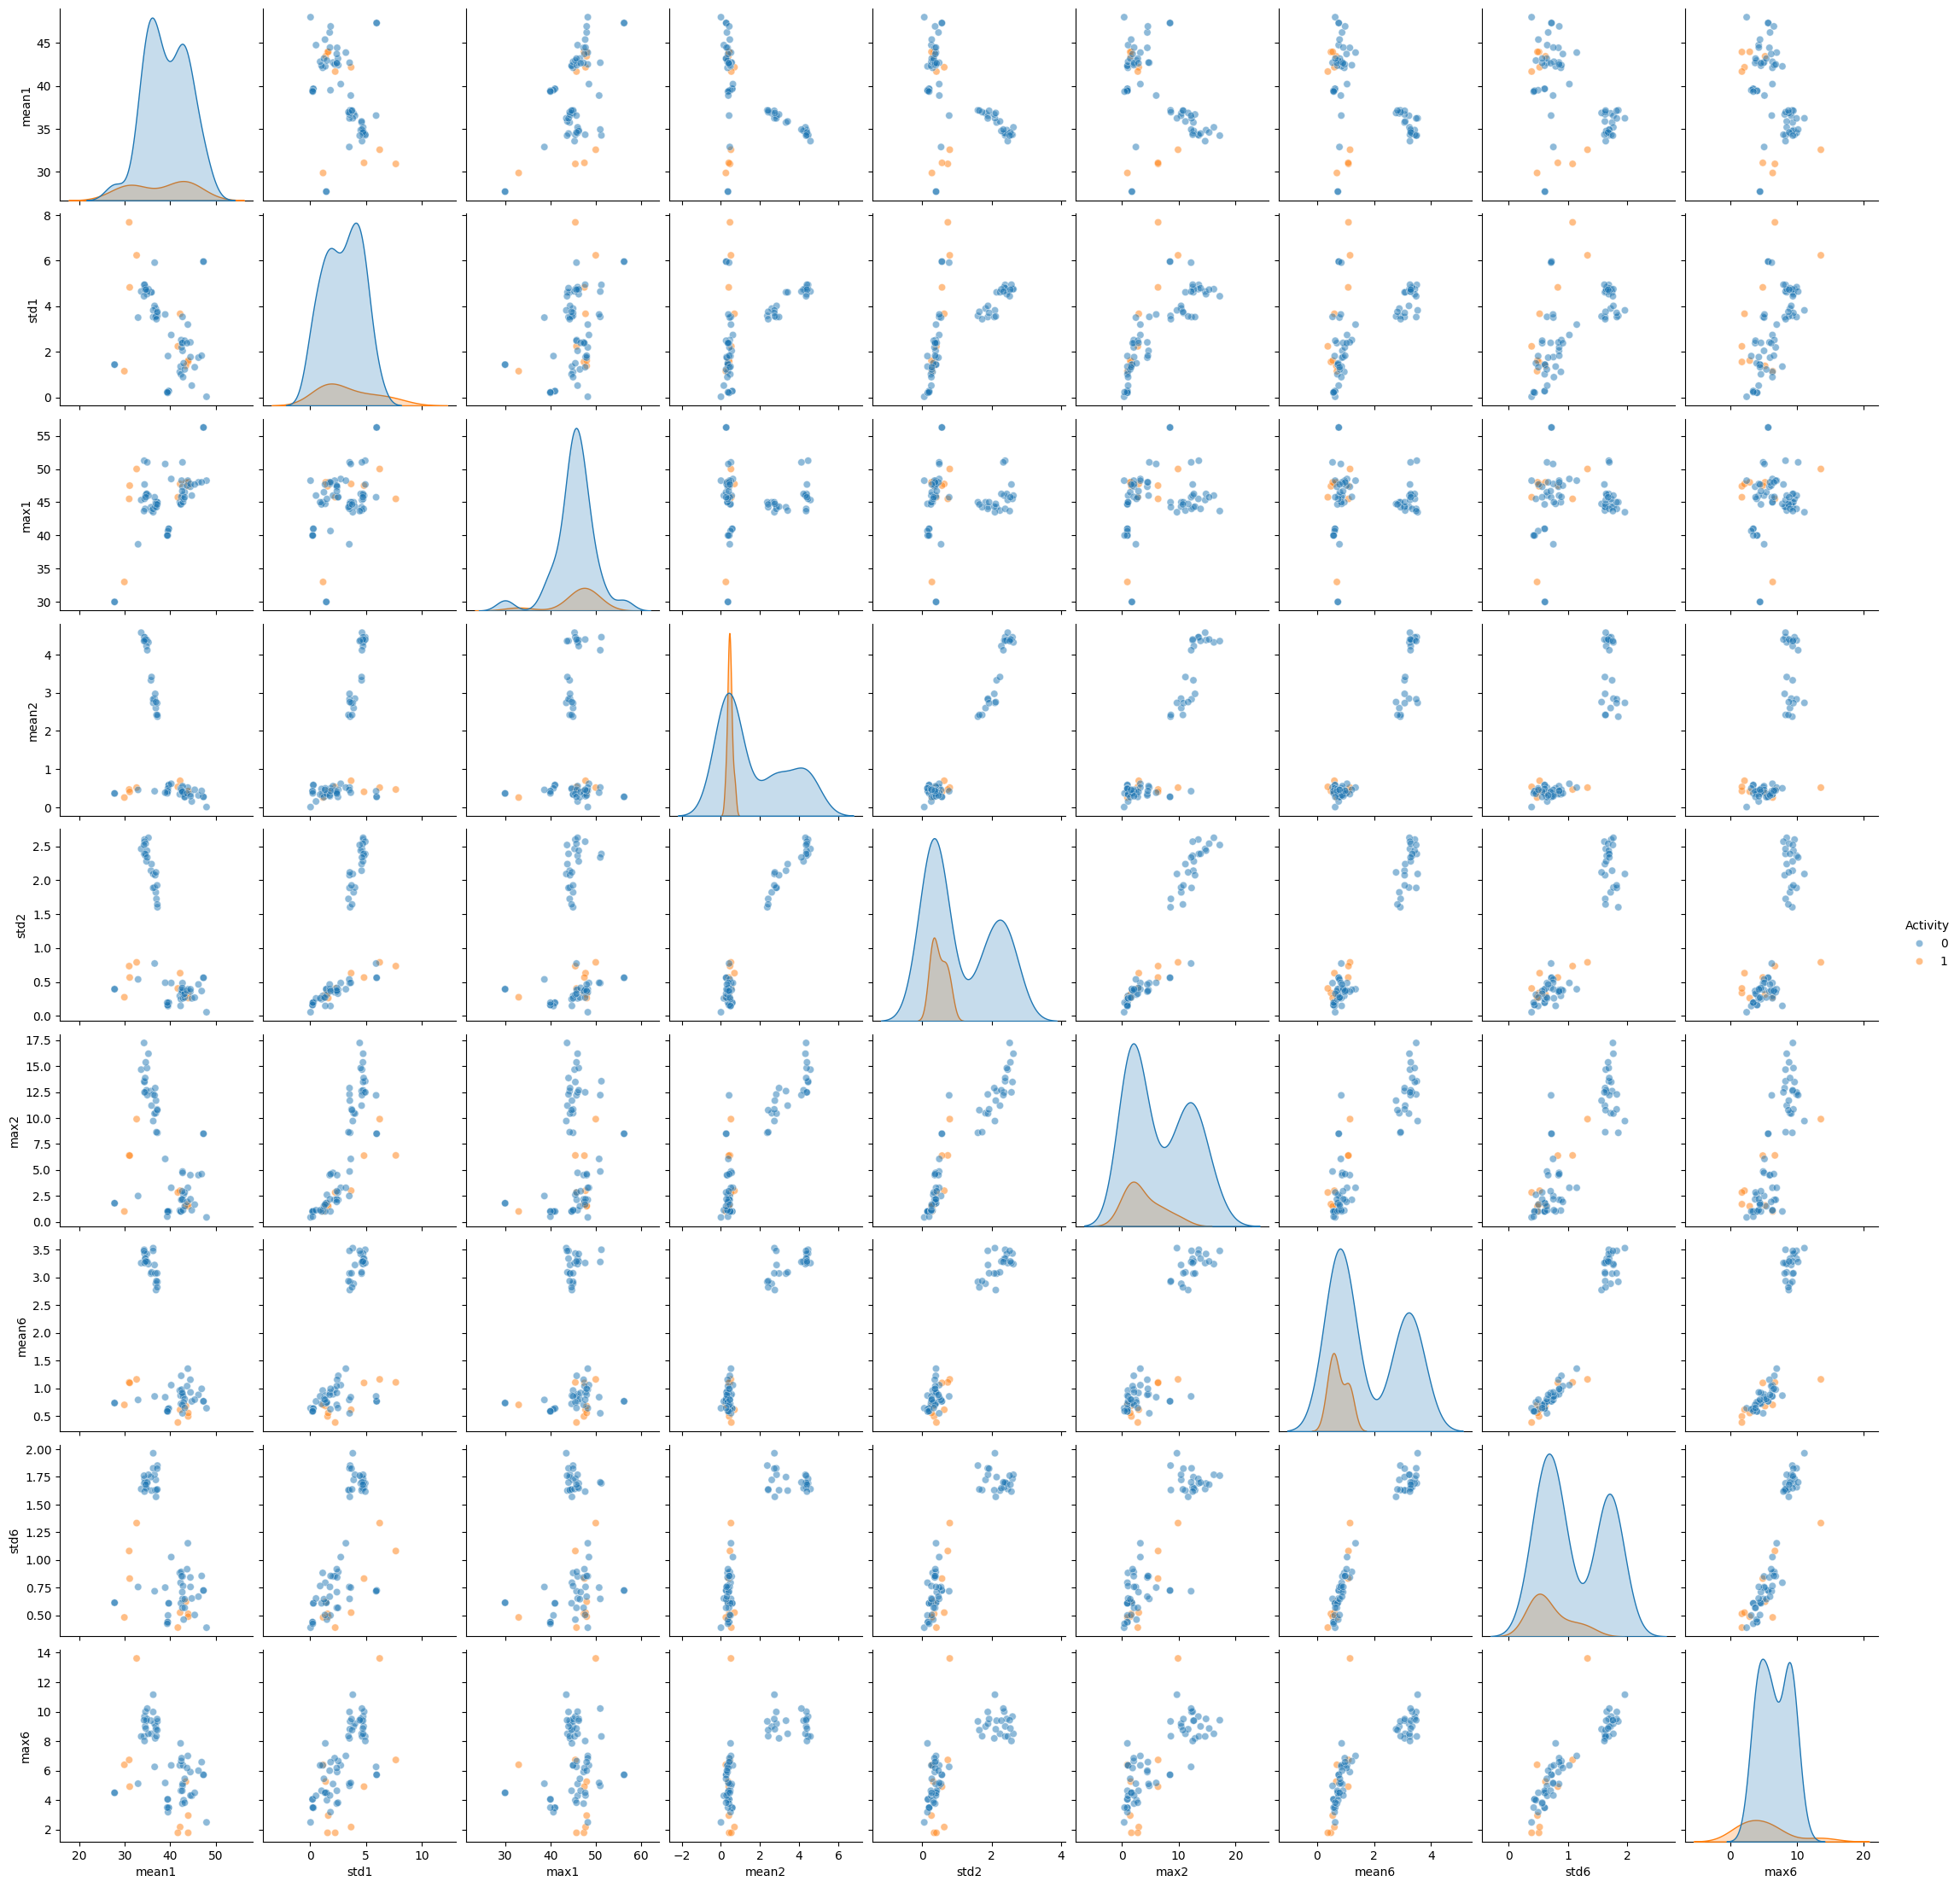

In [5]:
#get training data where Type = 0
train_binary = chart.loc[chart['Type'] == 0]
#test
#print(train_binary.shape)

#for simplicty, I changed my previous feature seletion in 1(c)iv from Range to Max
feature_filter = ['mean', 'std', 'max']
column_filter = ['1','2','6']
#column_filter = ['avg_rss12', 'var_rss_12', 'var_rss23']


#make column names for extraction
col_names = []
for col in column_filter:
    for feature in feature_filter:
       col_names.append(feature + col)
col_names.append('Activity')
#print(col_names)

#extract data 
train_binary_filter = train_binary[col_names]

#plot them!
sns.pairplot(train_binary_filter, hue="Activity", plot_kws={"alpha": 0.5})
plt.show()




#### ii. Split Plots

Break each time series in your training set into two (approximately) equal length time series. Now instead of 6 time series for each of the training instances, you have 12 time series for each training instance. Repeat the experiment in 2(a)i, i.e depict scatter plots of the features extracted from both parts of the time series 1,2, and 6. Do you see any considerable difference in the results with those of 2(a)i?

(69, 21)


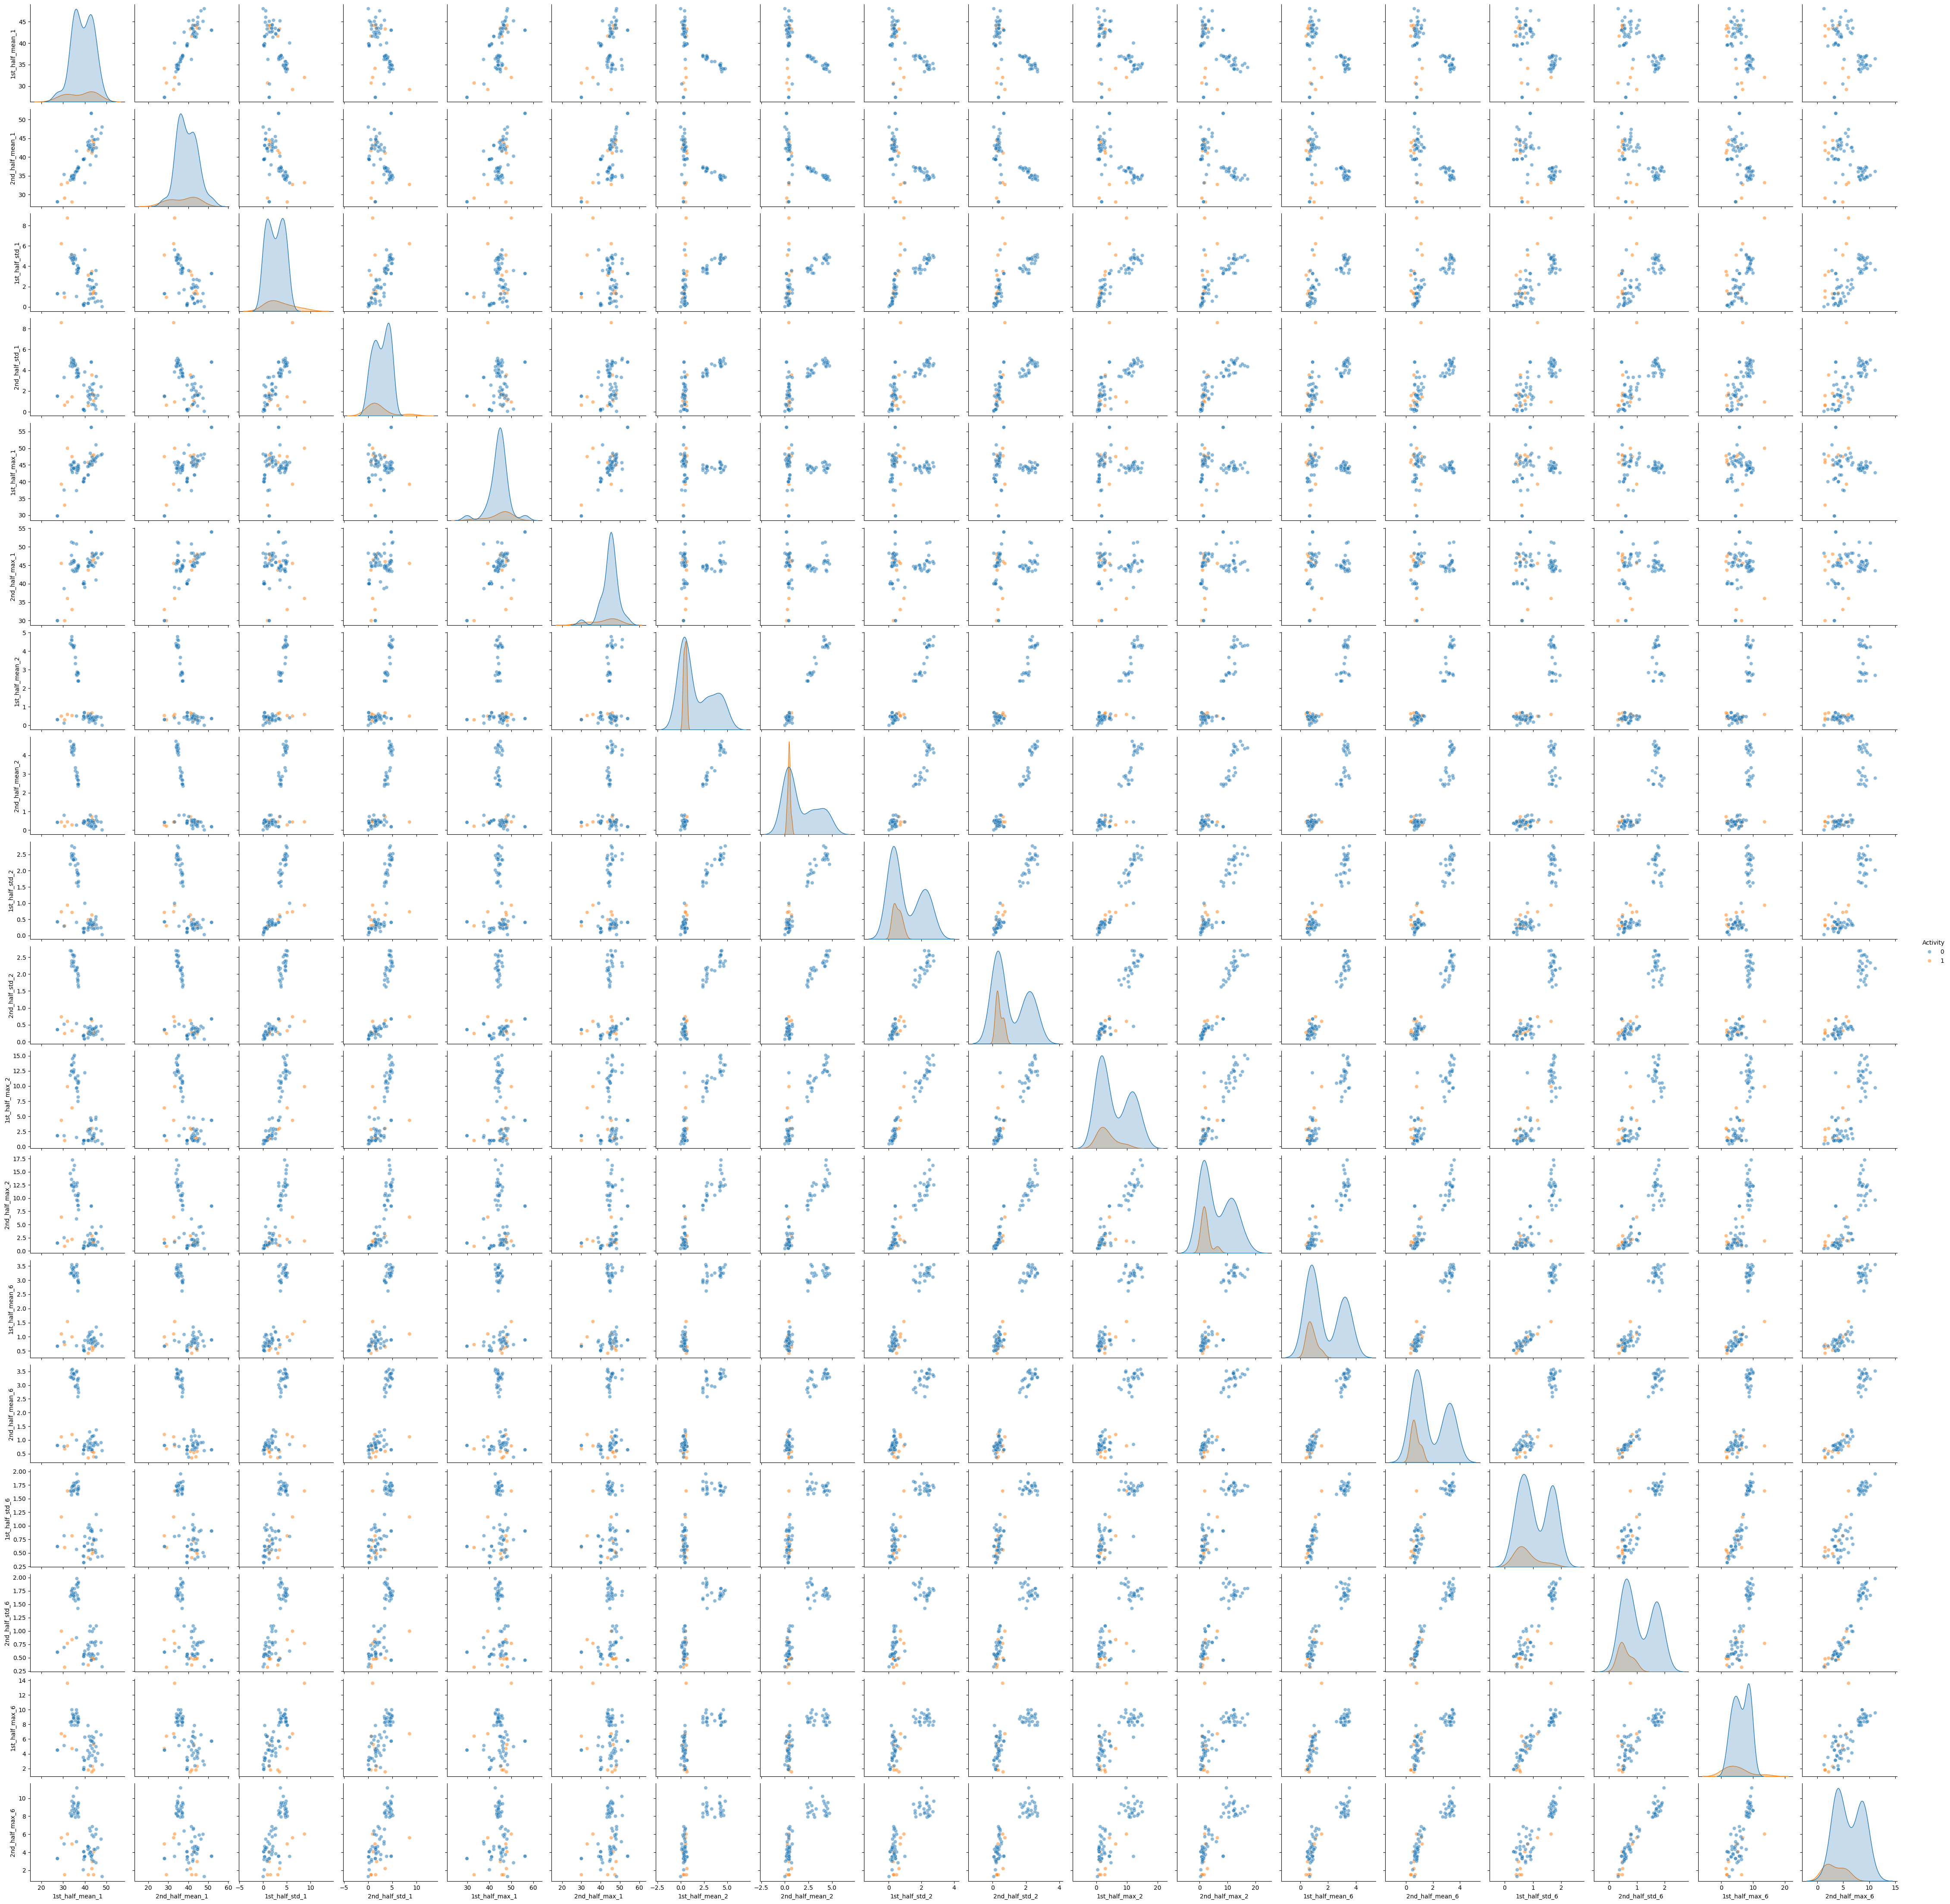

In [6]:
# Break each time series in your training set into two (approximately) equal length time series.
# Now instead of 6 time series for each of the training instances, you have 12 time series for each training instance.

chart_split = pd.DataFrame()

feature_filter = ['mean', 'std', 'max']
column_filter = ['1','2','6']

for j in range (88):
    chart_split.loc[j, "Instance"] = grouped_by_instance.get_group(j+1)['Instance'].iloc[0]
    chart_split.loc[j, "Activity"] = grouped_by_instance.get_group(j+1)['Activity'].iloc[0]
    chart_split.loc[j, "Type"] = grouped_by_instance.get_group(j+1)['Type'].iloc[0]

    chart_split.loc[j, "1st_half_mean_1"] = grouped_by_instance.get_group(j+1).iloc[:len(grouped_by_instance.get_group(j+1))//2, 1].mean()
    chart_split.loc[j, "2nd_half_mean_1"] = grouped_by_instance.get_group(j+1).iloc[len(grouped_by_instance.get_group(j+1))//2:, 1].mean()

    chart_split.loc[j, "1st_half_std_1"] = grouped_by_instance.get_group(j+1).iloc[:len(grouped_by_instance.get_group(j+1))//2, 1].std()
    chart_split.loc[j, "2nd_half_std_1"] = grouped_by_instance.get_group(j+1).iloc[len(grouped_by_instance.get_group(j+1))//2:, 1].std()

    chart_split.loc[j, "1st_half_max_1"] = grouped_by_instance.get_group(j+1).iloc[:len(grouped_by_instance.get_group(j+1))//2, 1].max()
    chart_split.loc[j, "2nd_half_max_1"] = grouped_by_instance.get_group(j+1).iloc[len(grouped_by_instance.get_group(j+1))//2:, 1].max()

    chart_split.loc[j, "1st_half_mean_2"] = grouped_by_instance.get_group(j+1).iloc[:len(grouped_by_instance.get_group(j+1))//2, 2].mean()
    chart_split.loc[j, "2nd_half_mean_2"] = grouped_by_instance.get_group(j+1).iloc[len(grouped_by_instance.get_group(j+1))//2:, 2].mean()
    
    chart_split.loc[j, "1st_half_std_2"] = grouped_by_instance.get_group(j+1).iloc[:len(grouped_by_instance.get_group(j+1))//2, 2].std()
    chart_split.loc[j, "2nd_half_std_2"] = grouped_by_instance.get_group(j+1).iloc[len(grouped_by_instance.get_group(j+1))//2:, 2].std()

    chart_split.loc[j, "1st_half_max_2"] = grouped_by_instance.get_group(j+1).iloc[:len(grouped_by_instance.get_group(j+1))//2, 2].max()
    chart_split.loc[j, "2nd_half_max_2"] = grouped_by_instance.get_group(j+1).iloc[len(grouped_by_instance.get_group(j+1))//2:, 2].max()

    chart_split.loc[j, "1st_half_mean_6"] = grouped_by_instance.get_group(j+1).iloc[:len(grouped_by_instance.get_group(j+1))//2, 6].mean()
    chart_split.loc[j, "2nd_half_mean_6"] = grouped_by_instance.get_group(j+1).iloc[len(grouped_by_instance.get_group(j+1))//2:, 6].mean()
    
    chart_split.loc[j, "1st_half_std_6"] = grouped_by_instance.get_group(j+1).iloc[:len(grouped_by_instance.get_group(j+1))//2, 6].std()
    chart_split.loc[j, "2nd_half_std_6"] = grouped_by_instance.get_group(j+1).iloc[len(grouped_by_instance.get_group(j+1))//2:, 6].std()

    chart_split.loc[j, "1st_half_max_6"] = grouped_by_instance.get_group(j+1).iloc[:len(grouped_by_instance.get_group(j+1))//2, 6].max()
    chart_split.loc[j, "2nd_half_max_6"] = grouped_by_instance.get_group(j+1).iloc[len(grouped_by_instance.get_group(j+1))//2:, 6].max()

   
#fix integer in Instance col
chart_split['Instance'] = chart_split['Instance'].astype(int)
chart_split['Activity'] = chart_split['Activity'].astype(int)

#filter for testing data
chart_split_testing = chart_split.loc[chart_split['Type'] == 0]
#display(chart_split_testing.head())
print(chart_split_testing.shape)
#plot them!
sns.pairplot(chart_split_testing.drop(columns=['Instance','Type']), hue="Activity", plot_kws={"alpha": 0.5})
plt.show()

##### Observation

*"Do you see any considerable difference in the results with those of 2(a)i?"* 

The time series was separated into two approximately equal parts, and the scatter plots now contain two feature separate observations for each original time series of the training instances. Compared with the plots in 2(a)i, the split-series plots show more observations and possibly show greater variation because each feature is calculated from only half of the original observations. However, the overall separation between bending and the "other activities" remains approximately the same. 

Therefore, splitting the time series does not appear to produce a noticable difference in class separation.



#### iii. Time Series Segments

Break each time series in your training set into l in {1, 2, ...., 20) time series of approximately equal length and use logistic regression to solve the binary classification problem, using time-domain features. Remember that breaking
each of the time series does not change the number of instances. It only changes the number of features for each instance. Calculate the p-values for your logistic regression parameters in each model corresponding to each value of l and refit a logistic regression model using your pruned set of features. Alternatively, you can use backward selection using sklearn.feature selection or glm in R. Use 5-fold cross-validation to determine the best value of the pair (l; p), where p is the number of features used in recursive feature elimination. Explain what the right way and the wrong way are to perform cross-validation in this problem. Obviously, use the right way! Also, you may encounter the problem of class imbalance, which may make some of your folds not having any instances of the rare class. In such a case, you can use stratified cross validation. Research what it means and use it if needed. 

In [7]:
#get training data
training_data = full_data.loc[full_data['Type'] == 0]

#print(segment_split.shape)
#display(training_data.head())
columns = ["avg_rss12","var_rss12","avg_rss13","var_rss13","avg_rss23","var_rss23"]

#print(X.shape)
#display(X.head())

#function to split the data l times
def split_cols(data, l, cols):
    #use np.array_split() to divide the series
    
    feature_rows = []
    labels = []
    instance_ids = []

    grouped = data.groupby("Instance", sort=True)
    for instance_id, group in grouped:
        
        row = {}
        label = int(group["Activity"].iloc[0])
    
        for series_number, col in enumerate(cols, start=1):
            values = (group[col]
                        .dropna()
                        .to_numpy(dtype=float)
                     )
            # Produces l approximately equal segments
            segments = np.array_split(values, l)
            
            for segment_number, segment in enumerate(segments, start=1):
                
                prefix = f"s{series_number}_part{segment_number}"
                row[f"{prefix}_min"] = np.min(segment)
                row[f"{prefix}_max"] = np.max(segment)
                row[f"{prefix}_mean"] = np.mean(segment)
                row[f"{prefix}_median"] = np.median(segment)
                row[f"{prefix}_std"] = (
                    np.std(segment, ddof=1)
                    if len(segment) > 1
                    else 0.0
                    )
                row[f"{prefix}_q1"] = np.quantile(segment, 0.25)
                row[f"{prefix}_q3"] = np.quantile(segment, 0.75)
        
        feature_rows.append(row)
        labels.append(label)
        instance_ids.append(instance_id)
    X = pd.DataFrame(feature_rows, index=instance_ids)
    y = pd.Series(labels, index=instance_ids, name="Type")
    
    # Protect the model against inf values
    X = X.replace([np.inf, -np.inf], np.nan)
    
    return X, y

results = []
outer_cv = StratifiedKFold(n_splits=5,shuffle=True, random_state=333)

inner_cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=333)


##### NOTE: Alternatively using backward selection using sklearn.feature selection

In [11]:
#for results
results = []

#Iterate l = {1, 2, ..., 20) times
for l in range(1, 21):

    # Call function to split columns l ways
    X_l, y_l = split_cols(data=train_data, l=l, cols=columns)

    rfe_estimator = Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler()),
        ("logit", LogisticRegression(penalty="l2", solver="liblinear", max_iter=10000, random_state=333))
    ])

    selector = RFECV( estimator=rfe_estimator, step=1, min_features_to_select=1, cv=inner_cv, scoring="accuracy", n_jobs=-1, importance_getter="named_steps.logit.coef_")

    cv_result = cross_validate( estimator=selector, X=X_l, y=y_l, cv=outer_cv, scoring={ "accuracy": "accuracy", "balanced_accuracy": "balanced_accuracy", "roc_auc": "roc_auc"},
        return_estimator=True, n_jobs=1, error_score="raise")

    p_by_fold = [int(fitted_selector.n_features_)  for fitted_selector in cv_result["estimator"] ]

    results.append({
        "l": l,
        "total_features": X_l.shape[1],
        "p_by_fold": p_by_fold,
        "mean_p": np.mean(p_by_fold),
        "median_p": np.median(p_by_fold),
        "mean_accuracy": np.mean(
            cv_result["test_accuracy"]
        ),
        "std_accuracy": np.std(
            cv_result["test_accuracy"],
            ddof=1
        ),
        "mean_bal_accuracy": np.mean(
            cv_result["test_balanced_accuracy"]
        ),
        "std_bal_accuracy": np.std(
            cv_result["test_balanced_accuracy"],
            ddof=1
        ),
        "mean_roc_auc": np.mean(
            cv_result["test_roc_auc"]
        ),
        "std_roc_auc": np.std(
            cv_result["test_roc_auc"],
            ddof=1
        )
    })

    print(f"Completed l={l:2d} | "
        f"features={X_l.shape[1]:3d} | "
        f"p={p_by_fold} | "
        f"accuracy={np.mean(cv_result['test_accuracy']):.4f}"
    )


results_df = pd.DataFrame(results)

results_df = results_df.sort_values(by=["mean_accuracy","mean_bal_accuracy","mean_p","l"], ascending=[False,False,True,True]).reset_index(drop=True)

display(results_df.round(4))

best_l = int(results_df.loc[0, "l"])

print(f"\nBest l: {best_l}")
print("Best mean CV accuracy: "f"{results_df.loc[0, 'mean_accuracy']:.4f}")
print("Mean balanced accuracy: "f"{results_df.loc[0, 'mean_bal_accuracy']:.4f}")
print("Mean ROC AUC: "f"{results_df.loc[0, 'mean_roc_auc']:.4f}")

# Recreate the feature matrix using the selected l
X_best, y_best = split_cols(data=train_data,l=best_l,cols=columns)

# Run RFECV on the complete training set to determineal p
final_rfe_estimator = Pipeline([("imputer", SimpleImputer(strategy="median")    ),
    ("scaler",StandardScaler()),
    ("logit",LogisticRegression(penalty="l2", solver="liblinear", max_iter=10000,random_state=333))
])

final_selector = RFECV(estimator=final_rfe_estimator, step=1, min_features_to_select=1, cv=inner_cv, scoring="accuracy", n_jobs=-1, importance_getter="named_steps.logit.coef_")
final_selector.fit(X_best, y_best)

best_p = final_selector.n_features_

selected_features = X_best.columns[final_selector.support_].tolist()

feature_selection_df = pd.DataFrame({"Feature": X_best.columns,"Selected": final_selector.support_,"RFE_Rank": final_selector.ranking_})

feature_selection_df = feature_selection_df.sort_values(by=["Selected", "RFE_Rank", "Feature"], ascending=[False, True, True]).reset_index(drop=True)

selected_features_df = feature_selection_df[feature_selection_df["Selected"]].reset_index(drop=True)

print(f"\nBest pair (l, p): ({best_l}, {best_p})")
print(f"Number of training instances: {X_best.shape[0]}")
print(f"Features before selection: {X_best.shape[1]}")
print(f"Features after selection: {best_p}")

display(selected_features_df)

# Create the final pruned training matrix
X_best_pruned = X_best.loc[:, selected_features]

# Fit the final logistic regression model
final_model = Pipeline([("imputer", SimpleImputer(strategy="median")),
    ("scaler",StandardScaler()),
    ("logit",LogisticRegression(penalty="l2", solver="liblinear", max_iter=10000,random_state=333))
])
final_model.fit(X_best_pruned, y_best)
final_coefficients = (final_model.named_steps["logit"].coef_[0])
coefficient_df = pd.DataFrame({"Feature": selected_features,"Coefficient": final_coefficients,"Absolute_Coefficient": np.abs(final_coefficients)})
coefficient_df = coefficient_df.sort_values(by="Absolute_Coefficient", ascending=False).reset_index(drop=True)

#display it!
display(coefficient_df.round(6)) 

Completed l= 1 | features= 42 | p=[2, 8, 1, 1, 6] | accuracy=0.9714
Completed l= 2 | features= 84 | p=[1, 5, 11, 1, 2] | accuracy=0.9275
Completed l= 3 | features=126 | p=[1, 11, 1, 1, 1] | accuracy=0.9560
Completed l= 4 | features=168 | p=[12, 5, 1, 1, 6] | accuracy=0.9418
Completed l= 5 | features=210 | p=[1, 7, 9, 1, 1] | accuracy=0.9275
Completed l= 6 | features=252 | p=[1, 10, 9, 2, 7] | accuracy=0.9275
Completed l= 7 | features=294 | p=[3, 7, 14, 1, 1] | accuracy=0.8989
Completed l= 8 | features=336 | p=[1, 6, 8, 1, 8] | accuracy=0.9132
Completed l= 9 | features=378 | p=[6, 16, 10, 2, 1] | accuracy=0.9132
Completed l=10 | features=420 | p=[8, 13, 11, 2, 2] | accuracy=0.9275
Completed l=11 | features=462 | p=[5, 6, 7, 1, 1] | accuracy=0.9275
Completed l=12 | features=504 | p=[5, 5, 9, 1, 3] | accuracy=0.9275
Completed l=13 | features=546 | p=[4, 1, 6, 9, 1] | accuracy=0.9846
Completed l=14 | features=588 | p=[1, 8, 1, 5, 1] | accuracy=0.9560
Completed l=15 | features=630 | p=[14, 

,l,total_features,p_by_fold,mean_p,median_p,mean_accuracy,std_accuracy,mean_bal_accuracy,std_bal_accuracy,mean_roc_auc,std_roc_auc
0,13,546,"[4, 1, 6, 9, 1]",4.2,4.0,0.9846,0.0344,0.9000,0.2236,1.0000,0.0000
1,1,42,"[2, 8, 1, 1, 6]",3.6,2.0,0.9714,0.0639,0.9000,0.2236,0.9625,0.0839
2,19,798,"[1, 1, 1, 1, 1]",1.0,1.0,0.9703,0.0407,0.8500,0.2236,1.0000,0.0000
3,3,126,"[1, 11, 1, 1, 1]",3.0,1.0,0.9560,0.0402,0.8417,0.2173,0.9667,0.0543
4,14,588,"[1, 8, 1, 5, 1]",3.2,1.0,0.9560,0.0402,0.8417,0.2173,0.9917,0.0186
5,17,714,"[1, 4, 9, 1, 1]",3.2,1.0,0.9560,0.0402,0.8417,0.2173,0.9833,0.0373
6,20,840,"[5, 1, 17, 1, 1]",5.0,1.0,0.9560,0.0402,0.8417,0.2173,1.0000,0.0000
7,18,756,"[6, 4, 1, 1, 2]",2.8,2.0,0.9560,0.0402,0.8000,0.2092,0.9917,0.0186
8,15,630,"[14, 4, 11, 3, 2]",6.8,4.0,0.9560,0.0402,0.8000,0.2092,0.9917,0.0186
9,4,168,"[12, 5, 1, 1, 6]",5.0,5.0,0.9418,0.0326,0.7917,0.1998,0.8250,0.3260



Best l: 13
Best mean CV accuracy: 0.9846
Mean balanced accuracy: 0.9000
Mean ROC AUC: 1.0000

Best pair (l, p): (13, 8)
Number of training instances: 69
Features before selection: 546
Features after selection: 8


,Feature,Selected,RFE_Rank
0,s1_part8_q3,True,1
1,s5_part12_min,True,1
2,s5_part2_mean,True,1
3,s5_part2_median,True,1
4,s5_part2_min,True,1
5,s5_part3_max,True,1
6,s6_part10_max,True,1
7,s6_part10_std,True,1


,Feature,Coefficient,Absolute_Coefficient
0,s5_part12_min,0.737122,0.737122
1,s5_part2_min,0.608414,0.608414
2,s5_part3_max,0.556716,0.556716
3,s1_part8_q3,-0.516582,0.516582
4,s5_part2_mean,0.510856,0.510856
5,s5_part2_median,0.482693,0.482693
6,s6_part10_max,-0.472817,0.472817
7,s6_part10_std,-0.442457,0.442457


Backward Selection Using sklearn.feature_selection sorted by Accuracy:
Best l: 13


##### Anwser:

The best pair (l, p) is (13, 8).

##### Explanation: 

##### The Right Way
The right way to perform cross-validation is to perform recursive feature elimination within each training fold. For each candidate pair (l,p)(l,p)(l,p), I used 5-fold stratified cross-validation. In each fold, RFE selected ppp features using only the four training folds, logistic regression was fitted using those selected features, and performance was evaluated on the remaining validation fold. The mean validation performance across the five folds was then used to compare the candidate (l,p)(l,p)(l,p) pairs. Stratified cross-validation was used to preserve the class proportions as closely as possible in each fold. The wrong way would be to perform feature selection on the entire training dataset before cross-validation and then cross-validate using those already-selected features. In that case, the validation observations would have influenced feature selection, causing data leakage. Feature selection must therefore occur independently within each cross-validation training fold.

##### Stratified Cross Validation
The binary classes were checked for class imbalance before cross-validation. Because an imbalanced dataset can result in folds containing very few or potentially no observations from the minority class, I used 5-fold stratified cross-validation. Stratified cross-validation preserves the proportion of observations belonging to each class in each fold as closely as possible. This helps ensure that both classes are represented when training and validating the logistic regression models. I therefore used StratifiedKFold(n_splits=5, shuffle=True, random_state=333) when evaluating each (l,p)(l,p)(l,p) pair.


#### iv. Confusion Matrix

Report the confusion matrix and show the ROC and AUC for your classifier on train data. Report the parameters of your logistic regression $\beta_i$'s as well as the p-values associated with them.

,Parameter,Coefficient,Std_Error,z_value,p_value
0,Intercept,-9.734136,15.929290,-0.611084,0.541144
1,s1_part8_q3,-2.703808,13.649156,-0.198093,0.842972
2,s5_part2_min,1.657417,43.288425,0.038288,0.969458
3,s5_part2_mean,1.712466,116.498405,0.014699,0.988272
4,s5_part2_median,1.072634,79.537351,0.013486,0.989240
5,s5_part3_max,3.359139,45.840602,0.073279,0.941584
6,s5_part12_min,3.191621,11.782464,0.270879,0.786484
7,s6_part10_max,-1.047963,86.995298,-0.012046,0.990389
8,s6_part10_std,-1.129506,81.802936,-0.013808,0.988983


Training Confusion Matrix:
[[60  0]
 [ 0  9]]


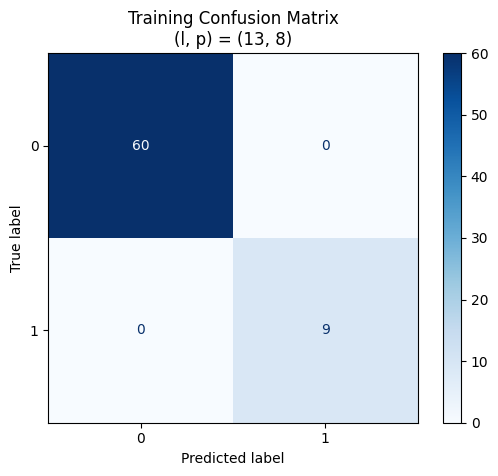

Training AUC: 1.0000


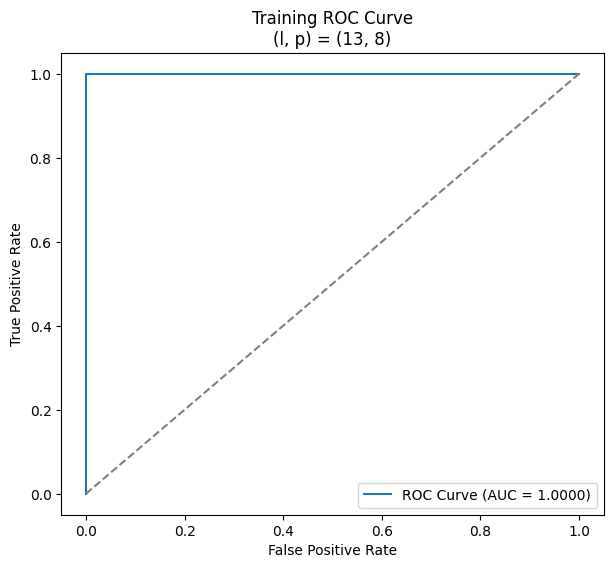

In [41]:
# Get only the features RFE selected
X_selected = X_best[selected_features].copy()

# New scaler specifically for these selected features
scaler_selected = StandardScaler()
X_selected_scaled = scaler_selected.fit_transform(X_selected)

# Fit unregularized logistic regression
logit = LogisticRegression(penalty=None, solver="lbfgs", max_iter=10000)
logit.fit(X_selected_scaled, y_best)

# Logistic regression parameters
beta = np.concatenate([logit.intercept_, logit.coef_[0]])

# Predicted probabilities
probabilities = logit.predict_proba(X_selected_scaled)[:, 1]

# Add intercept column
X_design = np.column_stack([np.ones(len(X_selected_scaled)), X_selected_scaled])

# Fisher information
W = probabilities * (1 - probabilities)
information_matrix = (X_design.T @ (X_design * W[:, None]))

# Covariance matrix
covariance_matrix = np.linalg.pinv(information_matrix)

# Standard errors
standard_errors = np.sqrt(np.diag(covariance_matrix))

# z statistics
z_values = beta / standard_errors

# p-values
p_values = 2 * norm.sf(np.abs(z_values))

# Results table
parameter_results = pd.DataFrame({"Parameter": ["Intercept"] + selected_features, "Coefficient": beta, "Std_Error": standard_errors, "z_value": z_values, "p_value": p_values})
display(parameter_results.round(6))

# Predictions on TRAINING DATA
y_train_pred = logit.predict(X_selected_scaled)

# Probability of class 1
y_train_prob = logit.predict_proba(X_selected_scaled)[:, 1]

# Confusion Matrix
cm = confusion_matrix(y_best, y_train_pred)

print("Training Confusion Matrix:")
print(cm)

ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=logit.classes_).plot(cmap="Blues", values_format="d")
plt.title(f"Training Confusion Matrix\n"f"(l, p) = ({best_l}, {best_p})")
plt.show()

# ROC Curve
fpr, tpr, thresholds = roc_curve(y_best, y_train_prob)

# AUC
train_auc = roc_auc_score(y_best, y_train_prob)
print(f"Training AUC: {train_auc:.4f}")

# Plot ROC
plt.figure(figsize=(7, 6))
plt.plot(fpr, tpr, label=f"ROC Curve (AUC = {train_auc:.4f})")

plt.plot([0, 1],[0, 1],linestyle="--",color="gray")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title(f"Training ROC Curve\n"f"(l, p) = ({best_l}, {best_p})")
plt.legend(loc="lower right")
plt.show()



#### v. Test Classifier

In [39]:

# get the test data, and split into the same number of parts that was selected using the training data
X_test, Y_test = split_cols(data=test_data,l=best_l,cols=columns)

# Extract the SAME features that were selected from the training data
X_test_selected = X_test[selected_features.copy()]

# Scale the test features using the scaler that was fitted on the TRAINING data
X_test_scaled = scaler_selected.transform(X_test_selected)

# Predict the test-set classes using the classifier that was fitted on the TRAINING data
y_test_pred = logit.predict(X_test_scaled)

# Calculate test accuracy
test_accuracy = accuracy_score(Y_test, y_test_pred)

# Get the cross-validation accuracy corresponding to the best value of l
cv_accuracy = results_df.loc[results_df["l"] == best_l, "mean_accuracy"].iloc[0]

# Compare test accuracy with CV accuracy
difference = test_accuracy - cv_accuracy

print(f"Best l: {best_l}")
print(f"Best p: {best_p}")
print(f"Cross-validation accuracy: {cv_accuracy:.4f}")
print(f"Test accuracy:             {test_accuracy:.4f}")
print(f"Test - CV accuracy:        {difference:+.4f}")

Best l: 13
Best p: 8
Cross-validation accuracy: 0.9846
Test accuracy:             0.9474
Test - CV accuracy:        -0.0372


##### Observation

The cross-validation accuracy is the same as from the previous calculation: .9846


#### vi. Separation

Do your classes seem to be well-separated to cause instability in calculating logistic regression parameters?

In [ ]:
##### Answer

Based on the results, there is evidence that my classes may be very well separated. The strongest clue is your earlier result:

$\quad$ Training AUC = 1.0000

An AUC of 1.0 means the fitted model perfectly ranks the two classes on the training data. That does not by itself prove complete separation, but combined with a perfect or nearly perfect training confusion matrix, 
it is a warning sign worth investigating. In logistic regression, complete separation occurs when a predictor or combination of predictors can perfectly separate the two outcome classes. In that situation, ordinary 
maximum-likelihood coefficient estimates may not have finite solutions and can become extremely large, with very large standard errors and unreliable p-values

#### vii. Imbalance

In [ ]:
From the confusion matrices you obtained, do you see imbalanced classes? If yes, build a logistic regression model based on case-control sampling and adjust its parameters. 
Report the confusion matrix, ROC, and AUC of the model.

Original training class distribution:
Class 0 (non-bending): 60 (86.96%)
Class 1 (bending):     9 (13.04%)

Yes, the classes are imbalanced.
The majority class has 60 instances, while the minority class has 9 instances.

Case-control sample:
Class 0 (non-bending): 9
Class 1 (bending):     9
Total observations:    18

Case-control parameter adjustment:
Original class-1 prevalence: 0.1304
Case-control class-1 prevalence: 0.5000
Unadjusted intercept: 1.605954
Intercept adjustment: -1.897120
Adjusted intercept: -0.291166


,Parameter,Before_Adjustment,After_Adjustment
0,Intercept,1.605954,-0.291166
1,s1_part8_q3,-4.178302,-4.178302
2,s5_part2_min,3.310673,3.310673
3,s5_part2_mean,3.476642,3.476642
4,s5_part2_median,2.555154,2.555154
5,s5_part3_max,3.433278,3.433278
6,s5_part12_min,2.590297,2.590297
7,s6_part10_max,-1.518952,-1.518952
8,s6_part10_std,-1.149324,-1.149324



Adjusted case-control model results on the original training data:

Confusion matrix:
[[60  0]
 [ 0  9]]

True negatives:  60
False positives: 0
False negatives: 0
True positives:  9
Accuracy:        1.0000


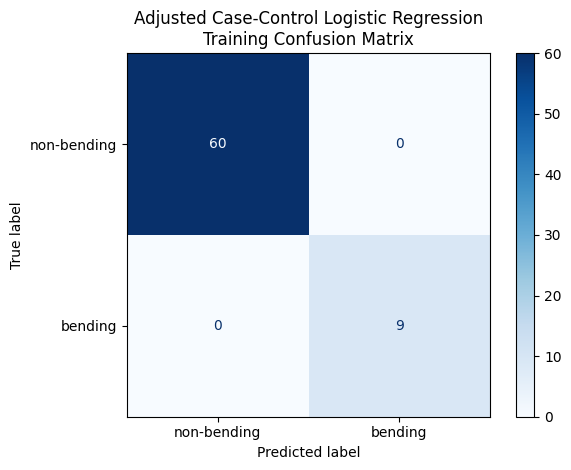

Adjusted case-control training AUC: 1.0000


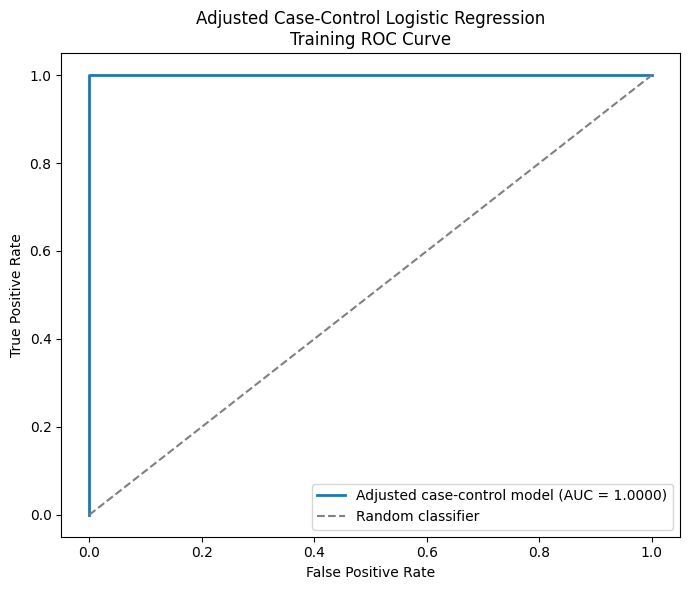

In [37]:

# Check for  imbalance

original_counts = y_best.value_counts().sort_index()
original_proportions = (y_best.value_counts(normalize=True).sort_index())

n_class_0 = int(original_counts.get(0, 0))
n_class_1 = int(original_counts.get(1, 0))

proportion_class_0 = float(original_proportions.get(0, 0))
proportion_class_1 = float(original_proportions.get(1, 0))
print("Original training class distribution:")
print(f"Class 0 (non-bending): "f"{n_class_0} ({proportion_class_0:.2%})")
print(f"Class 1 (bending):     "f"{n_class_1} ({proportion_class_1:.2%})")

class_counts = y_best.value_counts()
minority_class = int(class_counts.idxmin())
majority_class = int(class_counts.idxmax())
n_minority = int(class_counts.loc[minority_class])
n_majority = int(class_counts.loc[majority_class])

if n_minority == n_majority:
    print("\nNo, the classes are balanced.")
    print("Case-control sampling is not necessary.")
else:
    print()
    print("Yes, the classes are imbalanced.")
    print(f"The majority class has {n_majority} instances, "f"while the minority class has {n_minority} instances.")

    #Use the same features selected by RFE
    X_original = X_best.loc[:,selected_features].copy()
    y_original = y_best.copy()

    # Case-control sampling: Keep every minority-class observation abd randomly select the same number from the majority.
    minority_indices = y_original[y_original == minority_class].index.to_numpy()
    majority_indices = y_original[y_original == majority_class].index.to_numpy()

    rng = np.random.default_rng(333)

    sampled_majority_indices = rng.choice(majority_indices, size=n_minority, replace=False)

    case_control_indices = np.concatenate([minority_indices, sampled_majority_indices])

    # Shuffle the case-control observations
    rng.shuffle(case_control_indices)

    X_case_control = X_original.loc[case_control_indices].copy()

    y_case_control = y_original.loc[case_control_indices].copy()


    # Show clean case-control counts
    case_control_counts = (y_case_control.value_counts().sort_index())

    print("\nCase-control sample:")
    print(f"Class 0 (non-bending): "f"{int(case_control_counts.get(0, 0))}")
    print(f"Class 1 (bending):     "f"{int(case_control_counts.get(1, 0))}")
    print(f"Total observations:    "f"{len(y_case_control)}")

    # Standardize the case-control sample
    case_control_scaler = StandardScaler()
    X_case_control_scaled = (case_control_scaler.fit_transform(X_case_control))

    # Fit unregularized logistic regression
    case_control_model = LogisticRegression(penalty=None, solver="lbfgs", max_iter=10000, random_state=333)
    case_control_model.fit(X_case_control_scaled, y_case_control)

    # Adjust the intercept
    # pi = class-1 prevalence in the original data
    # q  = class-1 prevalence in the case-control sample
    # beta0_adjusted =
    # beta0_case_control + logit(pi) - logit(q)
    
    pi = float(np.mean(y_original == 1))
    q = float(np.mean(y_case_control == 1))
    intercept_adjustment = (np.log(pi / (1 - pi)) - np.log(q / (1 - q)))
    unadjusted_intercept = float(case_control_model.intercept_[0])
    adjusted_intercept = (unadjusted_intercept + intercept_adjustment)

    adjusted_slopes = (case_control_model.coef_[0].copy())

    # Report unadjusted and adjusted parameters; Only the intercept receives the prevalence correctio
    parameter_names = (["Intercept"] + selected_features)
    unadjusted_parameters = np.concatenate([[unadjusted_intercept],adjusted_slopes])


    adjusted_parameters = np.concatenate([[adjusted_intercept], adjusted_slopes])
    parameter_table = pd.DataFrame({"Parameter": parameter_names,"Before_Adjustment": unadjusted_parameters,"After_Adjustment": adjusted_parameters})

    print("\nCase-control parameter adjustment:")
    print(f"Original class-1 prevalence: "f"{pi:.4f}")
    print(f"Case-control class-1 prevalence: "f"{q:.4f}")
    print(f"Unadjusted intercept: "f"{unadjusted_intercept:.6f}")
    print(f"Intercept adjustment: "f"{intercept_adjustment:.6f}")
    print(f"Adjusted intercept: "f"{adjusted_intercept:.6f}")

    display(parameter_table.round(6))

    # Evaluate the adjusted model on all original training observations
    X_original_scaled = (case_control_scaler.transform(X_original))
    adjusted_log_odds = (adjusted_intercept + X_original_scaled @ adjusted_slopes)

    # Numerically stable logistic transformation
    adjusted_probabilities = np.empty_like(adjusted_log_odds, dtype=float)
    nonnegative = adjusted_log_odds >= 0
    adjusted_probabilities[nonnegative] = (1.0 / (1.0 + np.exp( -adjusted_log_odds[nonnegative])))
    exp_values = np.exp(adjusted_log_odds[~nonnegative])
    adjusted_probabilities[~nonnegative] = (exp_values / (1.0 + exp_values))
    adjusted_predictions = (adjusted_probabilities >= 0.50).astype(int)

    # Confusion matrix
    case_control_confusion_matrix = confusion_matrix(y_original, adjusted_predictions, labels=[0, 1])
    tn, fp, fn, tp = (case_control_confusion_matrix.ravel())
    case_control_accuracy = accuracy_score(y_original, adjusted_predictions)

    print("\nAdjusted case-control model results on the original training data:")
    print("\nConfusion matrix:")
    print(case_control_confusion_matrix)

    print(f"\nTrue negatives:  {tn}")
    print(f"False positives: {fp}")
    print(f"False negatives: {fn}")
    print(f"True positives:  {tp}")

    print(f"Accuracy:        "f"{case_control_accuracy:.4f}")

    ConfusionMatrixDisplay(confusion_matrix=case_control_confusion_matrix, display_labels=["non-bending","bending"]).plot(cmap="Blues", values_format="d")
    plt.title("Adjusted Case-Control Logistic Regression\n""Training Confusion Matrix")
    plt.tight_layout()
    plt.show()


    # ROC and AUC
    false_positive_rate, true_positive_rate, thresholds = (roc_curve(y_original,adjusted_probabilities,pos_label=1)    )
    case_control_auc = roc_auc_score(y_original, adjusted_probabilities)

    print(f"Adjusted case-control training AUC: "f"{case_control_auc:.4f}")

    plt.figure(figsize=(7, 6))
    plt.plot(false_positive_rate, true_positive_rate, linewidth=2, label=("Adjusted case-control model "f"(AUC = {case_control_auc:.4f})"))

    #random classifier
    plt.plot([0, 1],[0, 1],linestyle="--",color="gray",label="Random classifier")
    plt.xlabel("False Positive Rate")
    plt.ylabel("True Positive Rate")
    plt.title("Adjusted Case-Control Logistic Regression\n""Training ROC Curve")
    plt.legend(loc="lower right"    )

    plt.tight_layout()
    plt.show()

### (b) Binary Classification Using L1-penalized logistic regression

#### i. Time Series Segments

#### ii. Comparison

### (c) Multi-class Classification (The Realistic Case)

#### i. Time Series Segments

#### ii. Naive Bayes

#### ii. Comparison

## 3. ISLR 4.8.3

This problem relates to the QDA model, in which the observations within each class are drawn from a normal distribution with a class-specific
mean vector and a class specific covariance matrix. We consider the simple case where $p = 1$, i.e. there is only one feature.

Suppose that we have K classes, and that if an observation belongs to the kth class then X comes from a one-dimensional normal distribution,
X ∼ N($\mu_{k}, \sigma_K^2$). Recall that the density function for the one-dimensional normal distribution is given in (4.16). Prove that in this case, the Bayes classifier is *not linear*. Argue that it is in fact quadratic.

*Hint: For this problem, you should follow the arguments laid out in Section 4.4.1, but without making the assumption that $\sigma_1^2 = \cdots = \sigma_K^2$*

##### Notes

We want to prove that in this case the Bayes classifier is not linear but in fact quadratic when $p = 1$.

Since $p = 1$, we have only one feature, $X$, and $K$ possible classes. 

For class $K$, the normal denisty for:

$\quad X \mid Y = k \sim \mathcal{N}(\mu_k, \sigma_k^2)$ 

where:

- $k$ is the class
- $\mu_{k}$ is the mean of $X$ for $k$
- $\sigma_k^2$ is the variance of $X$ for $k$
- $\pi_k$ is the prior probability that an observation belongs to class $k$,
  
is:

$\quad f_k(x)=\frac{1}{\sqrt{2\pi\sigma_k^2}\!}\exp\left(-\frac{(x-\mu_k)^2}{2\sigma_k^2}\right)$

Applying logarithm to the equation produces:

$\quad \log f_k(x) = -\frac{1}{2}\log(2\pi) - \log \sigma_k - \frac{(x - \mu_k)^2}{2\sigma_k^2}$

Using the discriminate function:

$\quad \delta_k(x) = \log \pi_k + \log f_k(x)$

and subsituting $\log f_k(x)$ produces:

$\quad \delta_k(x) = \log \pi_k - \frac{1}{2}\log(2\pi) - \log \sigma_k - \frac{(x - \mu_k)^2}{2\sigma_k^2}$

which expanded is:

$\quad \delta_k(x) = \log \pi_k - \frac{1}{2}\log(2\pi) - \log \sigma_k - \frac{x^2 - 2x\mu_k + \mu_k^2}{2\sigma_k^2}$

Now, we simplify by distributing the denominator $2\sigma_k^2$:

$\quad \delta_k(x) = \log \pi_k - \frac{1}{2}\log(2\pi) - \log \sigma_k - \left(\frac{1}{2\sigma_k^2}\right)x^2 + \left(\frac{\mu_k}{\sigma_k^2}\right)x - \frac{\mu_k^2}{2\sigma_k^2}$

Rewritting in quadradic form $(\delta_k(x) = a_k x^2 + b_k x + c_k)$ produces:

$\quad \delta_k(x) = - \left(\frac{1}{2\sigma_k^2}\right)x^2 + \left(\frac{\mu_k}{\sigma_k^2}\right)x + \log \pi_k - \log \sigma_k - \frac{\mu_k^2}{2\sigma_k^2}  - \frac{1}{2}\log(2\pi)$

where:
- $a = \left(\frac{1}{2\sigma_k^2}\right)$
- $b = \left(\frac{\mu_k}{\sigma_k^2}\right)$
- $c = \log \pi_k - \log \sigma_k - \frac{\mu_k^2}{2\sigma_k^2}  - \frac{1}{2}\log(2\pi)$

##### Answer

Using the Bayes classifier with $p = 1$ produces a quadratic of $x$, and therefore it is quadratic.

## 4. ISLR 4.8.7

Suppose that we wish to predict whether a given stock will issue a dividend this year (“Yes” or “No”) based on X, last year’s percent profit. We examine a large number of companies and discover that the mean value of X for companies that issued a dividend was $\bar{X} = 10$, while the mean for those that didn’t was $\bar{X} = 0$. In addition, the variance of X for these two sets of companies was $\bar{σ}^2 = 36$. Finally, 80% of companies issued dividends. Assuming that X follows a normal distribution, predict the probability that a company will issue a dividend this year given that its percentage profit was X = 4 last year.

*Hint: Recall that the density function for a normal random variable is $f(x)=\frac{1}{\sqrt{2\pi\sigma^2}}e^{-\frac{(x-\mu)^2}{2\sigma^2}}$ . You will need to use Bayes’ theorem.*

##### Definitions

Bayes Theorem: $P(E_i \mid A) = \frac{P(E_i) \cdot P(A \mid E_i)}{\sum_{k=1}^n P(E_k) \cdot P(A \mid E_k)}$

From the problem, we derive:
    
$\quad P(Yes)$ = 0.80
    
$\quad P(No)$ = 0.20
    
$\quad \mu_{yes}$ = 10

$\quad \mu_{no} $ = 0

We must solve: $P(Yes | X = 4)$


##### Solving...

Using Bayes Theorem, we will have:

$\quad P(\text{Yes}\mid X=4)=
\frac{f_{\text{Yes}}(4)P(\text{Yes})}
{f_{\text{Yes}}(4)P(\text{Yes})+
f_{\text{No}}(4)P(\text{No})}$

Applying normal density, we have:

$\quad f_k(x) = \frac{1}{\sqrt{2\pi\sigma^2}} e\left(-\frac{(x-\mu_k)^2}{2\sigma^2}\right)$

For dividend issuing companies:

$\quad f_{\text{Yes}}(4)=\frac{1}{\sqrt{2\pi(36)}}e\left(-\frac{(4-10)^2}{2(36)}\right) = \frac{1}{\sqrt{72\pi}}e\left(-\frac{36}{72}\right)=\frac{1}{\sqrt{72\pi}}e^{-0.5}$

For non dividend issuing companies:

$\quad f_{\text{No}}(4) = \frac{1}{\sqrt{72\pi}}e^{-2/9} \approx 0.0532 $

Using the values in Bayes Theorem:

NOTE: $\frac{1}{\sqrt{72\pi}}$ is a common term and will factor out

$\quad P(Yes ∣ X=4)=\frac{.8e^{−.5}}{.8e^{−.5} + .2e^{-2/9}}$

Then:

$\quad P(Yes ∣ X=4)=\frac{.8(.6065)}{.8(.6065) + 0.2(.8007)} \approx .752$

##### Answer

$\quad P(Yes | X = 4) \approx .752$

The predicted probability of a company issuing a dividend is approximately 75.2%. Although X=4 is closer to the “No” mean of 0, the strong *prior probability* that 80% of companies issue dividends raises the *posterior probability* to about 75%.


## 5.1 Extra Practice 

Extra Practice (you do not need to submit the answers): ISLR 4.8.4, 4.8.9

#### ISLR 4.8.4

When the number of features p is large, there tends to be a deterioration in the performance of KNN and other local approaches that perform prediction using only observations that are near the test observation for which a prediction must be made. This phenomenon is known as the *curse of dimensionality*, and it ties into the fact that non-parametric approaches often perform poorly when p is large. We will now investigate this curse.

- (a) Suppose that we have a set of observations, each with measurements on $p = 1$ feature, $X$. We assume that $X$ is uniformly (evenly) distributed on $[0, 1]$. Associated with each observation is a response value. Suppose that we wish to predict a test observation’s response using only observations that are within 10 % of the range of X closest to that test observation. For instance, in order to predict the response for a test observation with $X = 0.6$, we will use observations in the range $[0.55, 0.65]$. On average, what fraction of the available observations will we use to make the prediction?

- (b) Now suppose that we have a set of observations, each with measurements on $p = 2$ features, $X_1$ and $X_2$. We assume that $X_1$ and $X_2$ are uniformly distributed on $[0, 1] × [0, 1]$. We wish to predict a test observation’s response using only observations that are within 10% of the range of $X_1$ and within 10% of the range of $X_2$ closest to that test observation. For instance, in order to predict the response for a test observation with $X_1 = 0.6$ and $X_2 = 0.35$, we will use observations in the range $[0.55, 0.65]$ for $X_1$ and in the range $[0.3, 0.4]$ for $X_2$. On average, what fraction of the available observations will we use to make the prediction?

- (c) Now suppose that we have a set of observations on $p = 100$ features. Again the observations are uniformly distributed on each feature, and again each feature ranges in value from 0 to 1. We wish to predict a test observation’s response using observations within the 10% of each feature’s range that is closest to that test observation. What fraction of the available observations will we use to make the prediction?

- (d) Using your answers to parts (a)–(c), argue that a drawback of KNN when p is large is that there are very few training observations
“near” any given test observation.

- (e) Now suppose that we wish to make a prediction for a test observation by creating a p-dimensional hypercube centered around the test observation that contains, on average, 10% of the training observations. For $p = 1, 2, and 100, what is the length of each side of the hypercube? Comment on your answer.

*Note: A hypercube is a generalization of a cube to an arbitrary number of dimensions. When p = 1, a hypercube is simply a line segment, when $p = 2$ it is a square, and when $p = 100$ it is a 100-dimensional cube.*



...

#### ISLR 4.8.9

This problem has to do with odds.
- (a) On average, what fraction of people with an odds of 0.37 of defaulting on their credit card payment will in fact default?
- (b) Suppose that an individual has a 16 % chance of defaulting on her credit card payment. What are the odds that she will default?

##### Answer
##### (a)

Odds are defined as: $\text{Odds}=\frac{P(\text{default})}{1-P(\text{default})}$

Let $p = P(default)$:

$\quad .37 = \frac{P(\text{default})}{1-P(\text{default})}$

Solve for $p$:

$\quad \begin{aligned} .37(1-p)& = p\\ .37-.37p&=p\\ .37 &= p + .37p = 1.37p\\ p& = \frac{.37}{1.37}\\ p&\approx .2701\end{aligned} $


##### (b)

The probability of defaulting is 16%, or .16. Using the Odds formula:

$\quad \text{Odds}=\frac{p}{1-p} $

Calcuate for $p = 16$:

$\quad \begin{aligned} \text{Odds}&=\frac{0.16}{1-0.16}\\ &=\frac{0.16}{0.84}\\ &\approx 0.1905 \end{aligned} $

The odds of her defaulting on her credit card payment is 19%, or .19:1.
